# Explore SWE observation-to-model quantile mapping

This notebook preprocesses point SWE observations into **model-equivalent** SWE. It does **not** bias-correct the model, alter the model state, or run data assimilation. The transformation direction is always observation space → model space.

$$
 y_{\mathrm{model\_equiv}}
 =
 F_{\mathrm{mod}}^{-1}\bigl(F_{\mathrm{obs}}(y_{\mathrm{obs}})\bigr)
$$

The observed climatological rank is preserved; the value is rewritten in the model's SWE climatology so it can later be compared directly to the model state.

## Step-by-step remapping

### 1. Align the two records in time, without filling gaps

Observations are Yukon snow-survey snow water equivalent (`mm`) from `data/yukon_snow_data.csv`, one value per `location_code` and `sample_date`. Modeled SWE is SUMMA `scalarSWE`, which is ~hourly. For each survey date we take only the **00:00** model value. There is no daily mean and no interpolation. If midnight is missing, that date is unpaired (`swe_model` is NaN).

The Ross run is lumped (one HRU). `DRAINAGE_PREFIX` keeps surveys whose `location_code` starts with `09BA` (Ross River drainage), so each station is colocated with that same midnight series. One millimetre of SWE equals one `kg m-2`.

The file already publishes Twin Creeks as a composite (`09BA-SC02`) and as the two courses (`09BA-SC02A`, `09BA-SC02B`). Those records are mapped separately. Quantile mapping stays station-specific: each course gets its own $F_{\mathrm{obs}}$ and $F_{\mathrm{mod}}$.

### 2. Decide what to do with this observation

For each station and each date:

1. Missing or negative observed SWE → no mapped value (`mapping_flag = 3`).
2. Observed SWE exactly **zero** → model-equivalent is **zero**. Quantile mapping is not applied. Snow-on / snow-off timing is not adjusted.
3. Observed SWE **positive** → continue to seasonal quantile mapping.

### 3. Build a seasonal calibration sample

Snow SWE is strongly seasonal, so we do not use one annual distribution.

For a target date, collect historical pairs whose **calendar day-of-year** is within $\pm$ `window_days` (default 30) of the target, using circular distance so 1 October includes late September:

$$
 \min\bigl(|d_1-d_2|,\, 366-|d_1-d_2|\bigr) \le \texttt{window\_days}.
$$

Only dates where **both** observed and midnight model SWE are finite enter the sample. Nothing is gap-filled.

If `cross_validate=True` (the default), drop every pair from the target **water year** (1 October start: 1 Oct 2015 is water year 2016). The target year does not help define its own mapping.

Then keep only pairs where **both** values are strictly positive. Zeros stay in the zero rule above; they do not enter $F_{\mathrm{obs}}$ or $F_{\mathrm{mod}}$.

If fewer than `min_samples` (default 20) positive pairs remain, the mapped value is missing (`mapping_flag = 2`). The window is not widened and other stations are not borrowed.

### 4. Estimate two empirical distributions

From those positive pairs, form two **independent** samples: the observed values and the modeled values. They share dates, but they are **sorted separately**. We do not regress obs on model, and we do not match pair-by-pair.

Sort each sample and assign Hazen plotting positions

$$
 p_i = \frac{i - 0.5}{n}, \qquad i = 1,\ldots,n.
$$

Tied SWE values are collapsed to one unique value with the **mean** plotting position of the tie, so the quantile grid is strictly increasing. Linear interpolation is used between those empirical quantiles. No parametric distribution is fitted.

### 5. Map the observation through those distributions

1. Find the observation's percentile in the observed CDF: $q = F_{\mathrm{obs}}(y_{\mathrm{obs}})$.
2. If $y_{\mathrm{obs}}$ is below (above) the calibration range, clip $q$ to the smallest (largest) supported plotting position. Tails are not extrapolated.
3. Read the model quantile function at that same percentile: $y_{\mathrm{model\_equiv}} = F_{\mathrm{mod}}^{-1}(q)$.

A high observation relative to the station's own winter climatology becomes a high value relative to the model's winter climatology, even if the two SWE scales differ.

### 6. Write the result beside the original observation

The original `snw` is kept. New fields include `swe_obs`, `swe_model_equivalent`, `quantile_obs`, `n_samples_mapping`, and `mapping_flag`.

Stations are also screened by how many **water years** have data (`MIN_YEARS`, default 5). Short records are still mapped for inspection and marked `passes_year_screen = False`.


In [1]:
from pathlib import Path

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from snowda.obs_qm import (
    FLAG_INSUFFICIENT_SAMPLES,
    FLAG_MAPPED,
    FLAG_MISSING_OBS,
    FLAG_ZERO_OBS,
    attach_mapped_variables,
    pair_obs_model,
    plot_station_diagnostics,
    preprocess_all_stations,
    station_record_table,
    stations_to_plot,
    read_midnight_model_swe,
    write_mapped_observations,
)

SWE_CSV = Path("/Users/dcasson/GitHub/snowda/data/yukon_snow_data.csv")
# Ross River drainage. These courses are colocated with the lumped Ross HRU.
# Set to "" to map every course in the Yukon file.
DRAINAGE_PREFIX = "09BA"
MODEL_PATH = Path(
    "/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/"
    "complete_ensemble_mean_run/summa/001_2024_12_29_timestep.nc"
)
OUT_DIR = Path("/Users/dcasson/GitHub/snowda/outputs/obs_qm")
OUT_NC = OUT_DIR / "ross_yukon_swe_model_equivalent.nc"

WINDOW_DAYS = 30
MIN_SAMPLES = 20
MIN_YEARS = 10
CROSS_VALIDATE = True
PLOT_SCREENED = False

## Observation inventory

Yukon snow-survey SWE is point snow water equivalent (`mm`) at `location_code`. Each station has a few survey dates per year, not a daily series.

`DRAINAGE_PREFIX = "09BA"` keeps the Ross River drainage courses. That includes the published Twin Creeks composite (`09BA-SC02`) and the separate A and B courses.

Screen stations by **water years with at least one finite observation** (`MIN_YEARS`). Short records remain in the maps and netCDF and are marked `passes_year_screen = False`; they are not plotted unless `PLOT_SCREENED` is `True`.

In [3]:
def read_yukon_swe(path: Path, drainage_prefix: str = "") -> xr.Dataset:
    """Snow-survey SWE as ``snw(time, station_id)``, in mm.

    The CSV preamble is skipped by finding the ``location_code`` header.
    ``sample_date`` is the observation time. Missing station-dates stay NaN.
    """
    with path.open() as handle:
        skip = next(
            i for i, line in enumerate(handle) if line.startswith("location_code,")
        )
    raw = pd.read_csv(path, skiprows=skip)
    swe = raw.loc[raw["parameter"].eq("snow water equivalent")].copy()
    if drainage_prefix:
        swe = swe.loc[swe["location_code"].astype(str).str.startswith(drainage_prefix)]
    if swe.empty:
        raise ValueError(
            f"No snow-water-equivalent rows in {path} for prefix {drainage_prefix!r}."
        )
    if not swe["units"].eq("mm").all():
        raise ValueError(
            f"Expected SWE in mm, found {sorted(swe['units'].dropna().unique())}"
        )
    swe["sample_date"] = pd.to_datetime(swe["sample_date"], errors="coerce")
    swe["result"] = pd.to_numeric(swe["result"], errors="coerce")
    swe = swe.dropna(subset=["sample_date", "result", "location_code"])
    wide = (
        swe.pivot_table(
            index="sample_date",
            columns="location_code",
            values="result",
            aggfunc="mean",
        )
        .sort_index()
    )
    names = (
        swe.drop_duplicates("location_code")
        .set_index("location_code")["location_name"]
        .reindex(wide.columns)
    )
    ds = xr.Dataset(
        {"snw": (("time", "station_id"), wide.to_numpy(dtype=float))},
        coords={
            "time": wide.index.to_numpy(),
            "station_id": wide.columns.astype(str).to_numpy(),
            "station_name": ("station_id", names.astype(str).to_numpy()),
        },
    )
    ds["snw"].attrs.update(
        {
            "units": "mm",
            "long_name": "snow water equivalent",
            "source": str(path),
        }
    )
    ds.attrs["source"] = str(path)
    ds.attrs["obs_variable"] = "snw"
    ds.attrs["drainage_prefix"] = drainage_prefix
    return ds


obs_ds = read_yukon_swe(SWE_CSV, drainage_prefix=DRAINAGE_PREFIX)
snw = obs_ds["snw"]
print(obs_ds)
print()
print("time:", obs_ds.time.values[0], "->", obs_ds.time.values[-1])

coverage = station_record_table(snw, min_years=MIN_YEARS)
rows = []
for sid in obs_ds.station_id.values:
    v = snw.sel(station_id=sid).values
    finite = np.isfinite(v)
    cov = coverage.set_index("station_id").loc[sid]
    rows.append(
        {
            "station_id": sid,
            "name": str(obs_ds["station_name"].sel(station_id=sid).values),
            "n_finite": int(finite.sum()),
            "n_zero": int(((v == 0) & finite).sum()),
            "n_positive": int((v > 0).sum()),
            "n_calendar_years": int(cov["n_calendar_years"]),
            "n_water_years": int(cov["n_water_years"]),
            "first_year": cov["first_year"],
            "last_year": cov["last_year"],
            "passes_year_screen": bool(cov["passes_year_screen"]),
            "min": float(np.nanmin(v)) if finite.any() else np.nan,
            "max": float(np.nanmax(v)) if finite.any() else np.nan,
        }
    )
pd.DataFrame(rows)

<xarray.Dataset> Size: 21kB
Dimensions:       (time: 325, station_id: 7)
Coordinates:
  * time          (time) datetime64[ns] 3kB 1975-03-03 1975-04-04 ... 2026-04-29
  * station_id    (station_id) object 56B '09BA-SC01' ... '09BA-SC05'
    station_name  (station_id) object 56B 'Ross River Hill Snow Course' ... '...
Data variables:
    snw           (time, station_id) float64 18kB 66.0 nan nan ... 320.0 118.0
Attributes:
    source:           /Users/dcasson/GitHub/snowda/data/yukon_snow_data.csv
    obs_variable:     snw
    drainage_prefix:  09BA

time: 1975-03-03T00:00:00.000000000 -> 2026-04-29T00:00:00.000000000


,station_id,name,n_finite,n_zero,n_positive,n_calendar_years,n_water_years,first_year,last_year,passes_year_screen,min,max
0,09BA-SC01,Ross River Hill Snow Course,49,11,38,11,11,1975.0,1985.0,True,0.0,150.0
1,09BA-SC02,Twin Creeks Snow Course (composite),174,13,161,50,50,1977.0,2026.0,True,0.0,346.0
2,09BA-SC02A,Twin Creeks A Snow Course,163,13,150,46,46,1977.0,2026.0,True,0.0,346.0
3,09BA-SC02B,Twin Creeks B Snow Course,32,0,32,11,11,2016.0,2026.0,True,44.0,307.0
4,09BA-SC03,Hoole River Snow Course,175,21,154,50,50,1977.0,2026.0,True,0.0,269.0
5,09BA-SC04,Burns Lake Snow Course,129,4,125,41,41,1986.0,2026.0,True,0.0,395.0
6,09BA-SC05,Finlayson Airstrip Snow Course,129,17,112,40,40,1987.0,2026.0,True,0.0,218.0


## Midnight model SWE

SUMMA `scalarSWE` is ~hourly. Pairing uses the **00:00** instantaneous value only. Days without a midnight sample stay unpaired (no averaging, no interpolation). The Ross file is lumped (one HRU), so every station is colocated with that HRU.

In [4]:
model = read_midnight_model_swe(MODEL_PATH)
print(model)
print("midnight time:", model.time.values[0], "->", model.time.values[-1])
print("n midnight days:", model.sizes["time"])
print("units:", model.attrs.get("units"))
print("min/max:", float(model.min()), float(model.max()))

<xarray.DataArray 'swe_model' (time: 16435)> Size: 131kB
array([ 6.4272072 ,  6.1483749 ,  7.0416528 , ..., 68.22014326,
       68.63335324, 68.81829811], shape=(16435,))
Coordinates:
    hru      int32 4B 1
  * time     (time) datetime64[ns] 131kB 1980-01-01 1980-01-02 ... 2024-12-29
Attributes:
    long_name:             snow water equivalent (instant)
    units:                 kg m-2
    model_time_selection:  midnight
    midnight_tolerance:    0 days 00:01:00
    source:                /Users/dcasson/GitHub/snowda/outputs/ross_summa_de...
    model_variable:        scalarSWE
midnight time: 1980-01-01T00:00:00.000000000 -> 2024-12-29T00:00:00.000000000
n midnight days: 16435
units: kg m-2
min/max: 0.0 253.2990265748449


In [5]:
pair_rows = []
for sid in obs_ds.station_id.values:
    paired = pair_obs_model(snw.sel(station_id=sid), model)
    obs_finite = np.isfinite(paired["swe_obs"].values)
    pair_rows.append(
        {
            "station_id": sid,
            "n_obs_times": int(paired.attrs["n_obs_times"]),
            "n_obs_finite": int(obs_finite.sum()),
            "n_paired": int(paired.attrs["n_paired"]),
            "n_finite_obs_missing_midnight": int(
                paired.attrs["n_unpaired_missing_model"]
            ),
        }
    )
pd.DataFrame(pair_rows)

,station_id,n_obs_times,n_obs_finite,n_paired,n_finite_obs_missing_midnight
0,09BA-SC01,325,49,29,20
1,09BA-SC02,325,174,154,20
2,09BA-SC02A,325,163,143,20
3,09BA-SC02B,325,32,26,6
4,09BA-SC03,325,175,155,20
5,09BA-SC04,325,129,124,5
6,09BA-SC05,325,129,123,6


## Map observations into model space

Each station is mapped independently. Default cross-validation leaves out the target water year (1 October start) when building $F_{\mathrm{obs}}$ and $F_{\mathrm{mod}}$.

In [6]:
mapped = preprocess_all_stations(
    snw,
    model,
    window_days=WINDOW_DAYS,
    min_samples=MIN_SAMPLES,
    min_years=MIN_YEARS,
    cross_validate=CROSS_VALIDATE,
)
mapped

<xarray.Dataset> Size: 90kB
Dimensions:                 (station_id: 7, time: 325)
Coordinates:
  * station_id              (station_id) object 56B '09BA-SC01' ... '09BA-SC05'
  * time                    (time) datetime64[ns] 3kB 1975-03-03 ... 2026-04-29
Data variables: (12/17)
    swe_obs                 (station_id, time) float64 18kB 66.0 76.0 ... 118.0
    swe_model               (station_id, time) float64 18kB nan nan ... nan nan
    swe_model_equivalent    (station_id, time) float64 18kB nan nan ... 183.2
    quantile_obs            (station_id, time) float64 18kB nan nan ... 0.702
    n_samples_mapping       (station_id, time) int32 9kB 13 12 13 11 ... 0 71 50
    mapping_flag            (station_id, time) int8 2kB 2 2 2 2 2 ... 0 0 3 0 0
    ...                      ...
    n_calendar_years        (station_id) float64 56B 11.0 50.0 ... 41.0 40.0
    n_water_years           (station_id) float64 56B 11.0 50.0 ... 41.0 40.0
    n_water_years_positive  (station_id) float64 56B 11.0 50.0 ... 41.0 40.0
    first_year              (station_id) float64 56B 1.975e+03 ... 1.987e+03
    last_year               (station_id) float64 56B 1.985e+03 ... 2.026e+03
    passes_year_screen      (station_id) bool 7B True True True ... True True
Attributes:
    mapping_method:          empirical_quantile_mapping
    mapping_direction:       observation_to_model
    seasonal_window_days:    30
    cross_validation:        leave_one_water_year_out
    min_samples:             20
    water_year_start_month:  10
    plotting_position:       hazen_(i-0.5)/n
    model_time_selection:    midnight
    min_years:               10
    station_pooling:         none

In [7]:
flag_names = {
    int(FLAG_MAPPED): "mapped",
    int(FLAG_ZERO_OBS): "zero_obs",
    int(FLAG_INSUFFICIENT_SAMPLES): "insufficient_samples",
    int(FLAG_MISSING_OBS): "missing_obs",
}
summary = []
for sid in mapped.station_id.values:
    sub = mapped.sel(station_id=sid)
    flags, counts = np.unique(sub["mapping_flag"].values, return_counts=True)
    row = {
        "station_id": sid,
        "n_paired": float(sub["n_paired"]),
        "n_water_years": int(sub["n_water_years"]),
        "passes_year_screen": bool(sub["passes_year_screen"]),
        "obs_zero_fraction": float(sub["obs_zero_fraction"]),
        "model_zero_fraction": float(sub["model_zero_fraction"]),
        "both_positive_fraction": float(sub["both_positive_fraction"]),
    }
    for flag, n in zip(flags, counts):
        row[flag_names.get(int(flag), str(int(flag)))] = int(n)
    summary.append(row)
pd.DataFrame(summary).fillna(0)

,station_id,n_paired,n_water_years,passes_year_screen,obs_zero_fraction,model_zero_fraction,both_positive_fraction,zero_obs,insufficient_samples,missing_obs,mapped
0,09BA-SC01,29.0,11,True,0.206897,0.034483,0.793103,11.0,38.0,276,0.0
1,09BA-SC02,154.0,50,True,0.071429,0.019481,0.928571,13.0,0.0,151,161.0
2,09BA-SC02A,143.0,46,True,0.076923,0.020979,0.923077,13.0,0.0,162,150.0
3,09BA-SC02B,26.0,11,True,0.000000,0.000000,1.000000,0.0,32.0,293,0.0
4,09BA-SC03,155.0,50,True,0.116129,0.012903,0.883871,21.0,0.0,150,154.0
5,09BA-SC04,124.0,41,True,0.032258,0.016129,0.967742,4.0,0.0,196,125.0
6,09BA-SC05,123.0,40,True,0.138211,0.008130,0.861789,17.0,0.0,196,112.0


## Station diagnostics

One figure per station that **passes the year screen**: four comparison panels (positive SWE distributions; observed vs model-equivalent and same-day model vs mapped obs, both coloured by held-out water year; Q-Q of mapped obs vs model climatology) and a full-width timeseries of every midnight model SWE value, the observations, and the observations in model space.

Screened stations stay in the tables and netCDF. Set `PLOT_SCREENED = True` to draw them too. Sparse survey windows with `insufficient_samples` are expected; that is not a silent fallback.

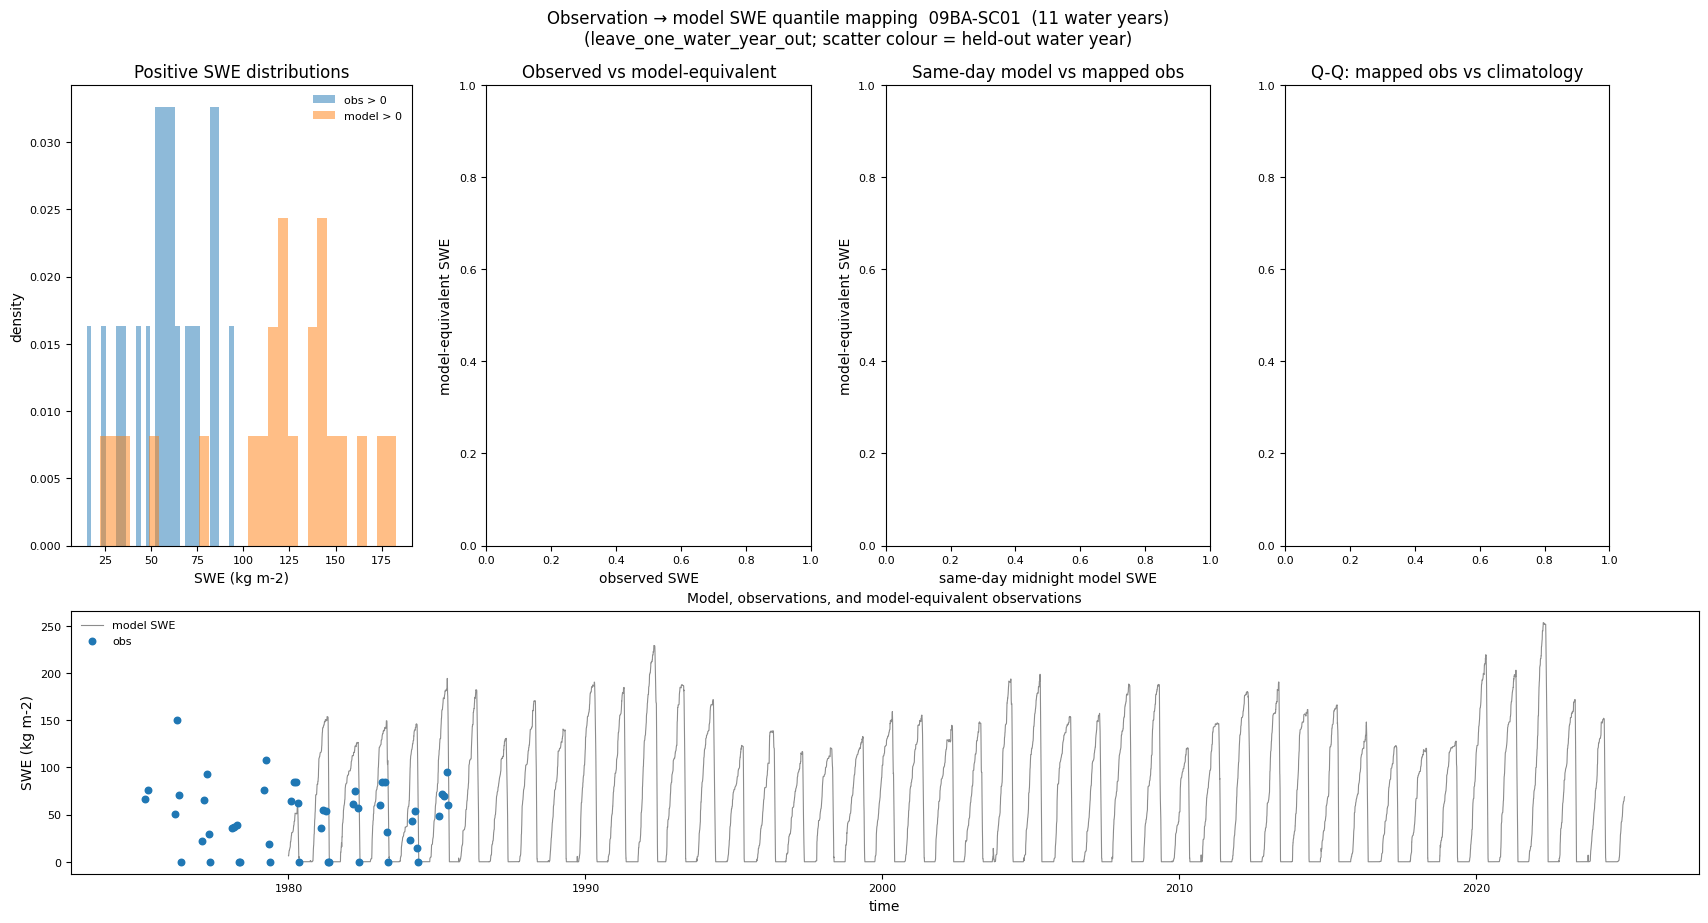

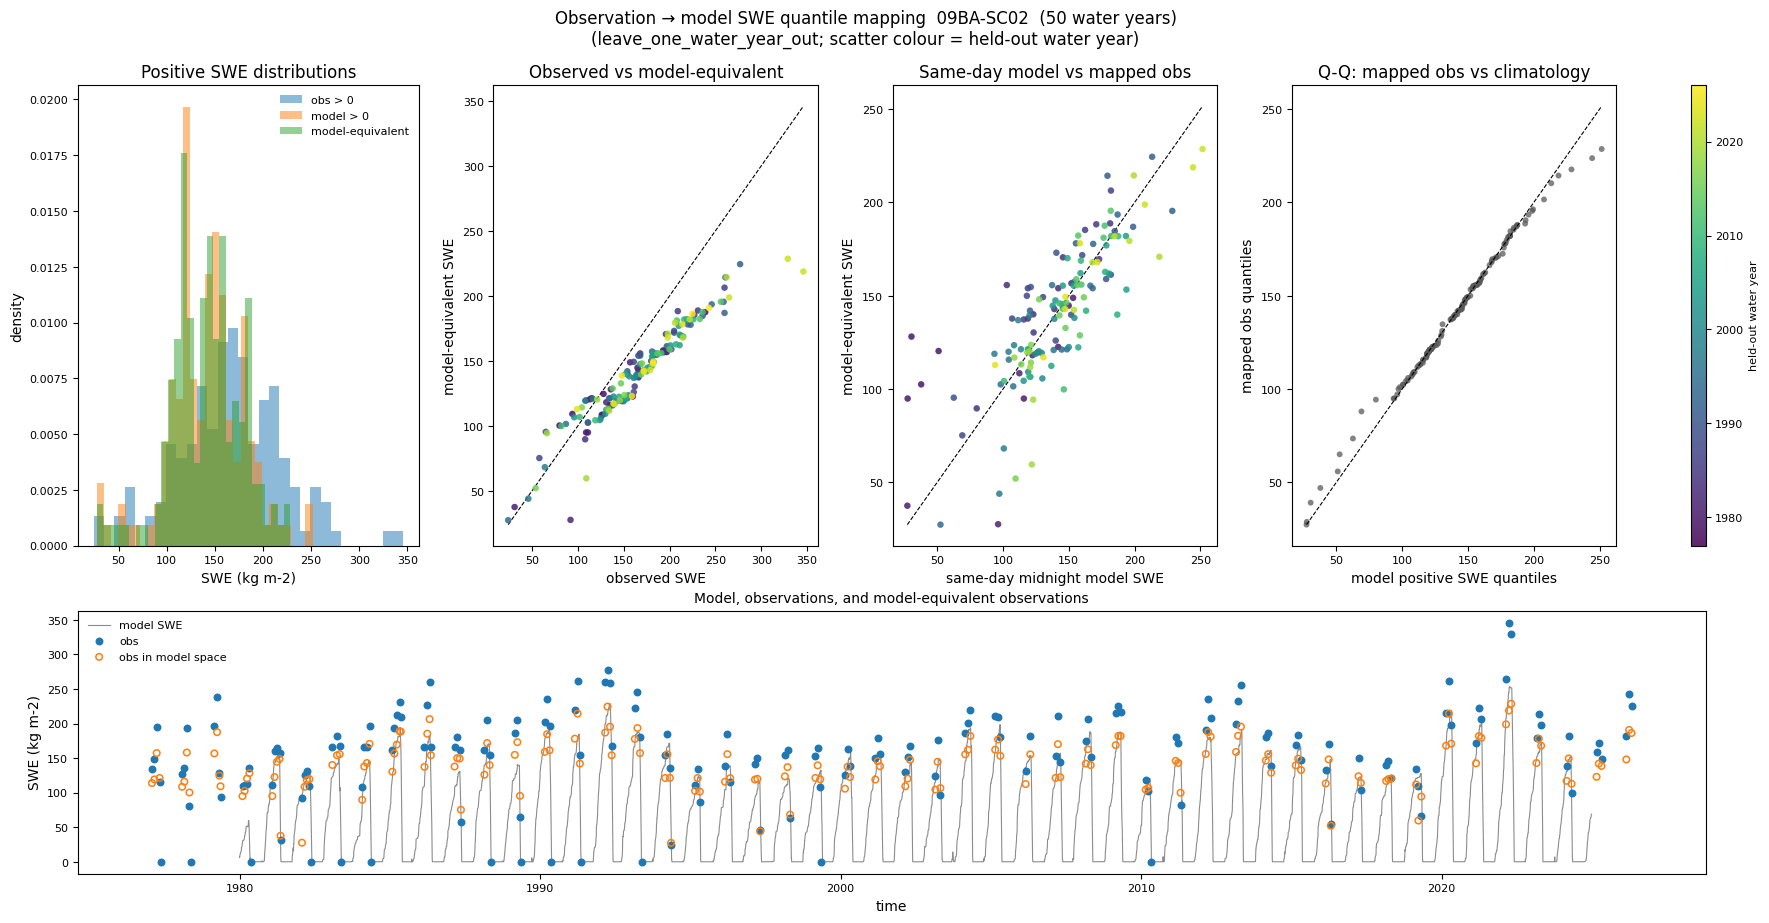

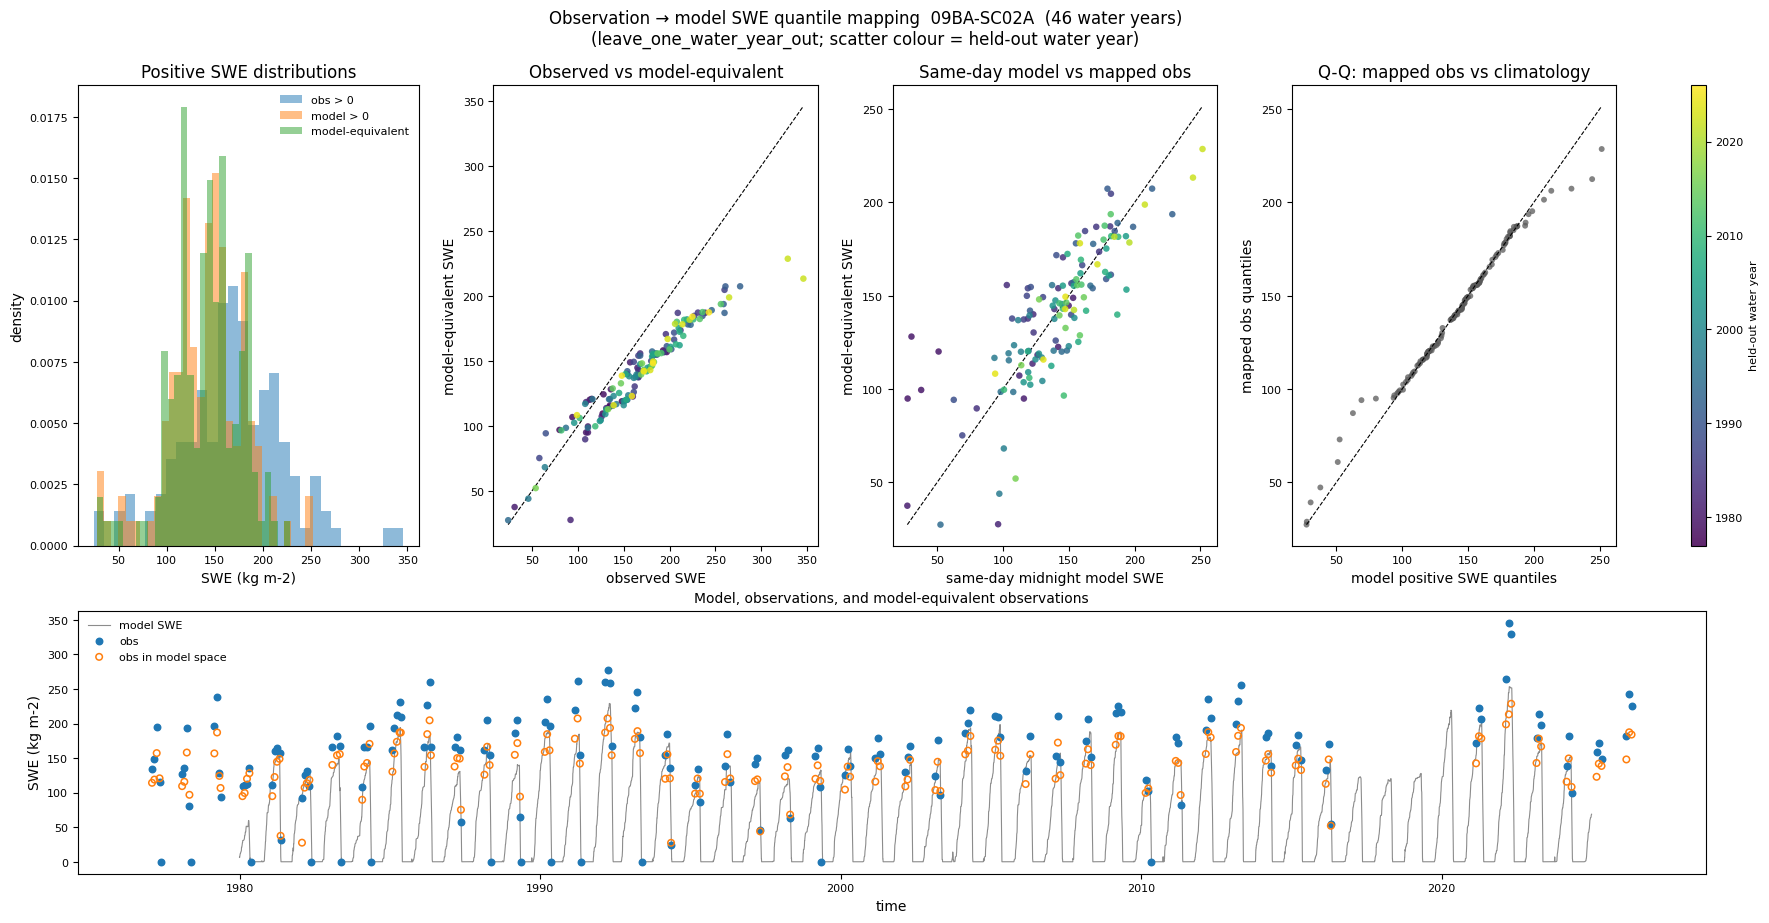

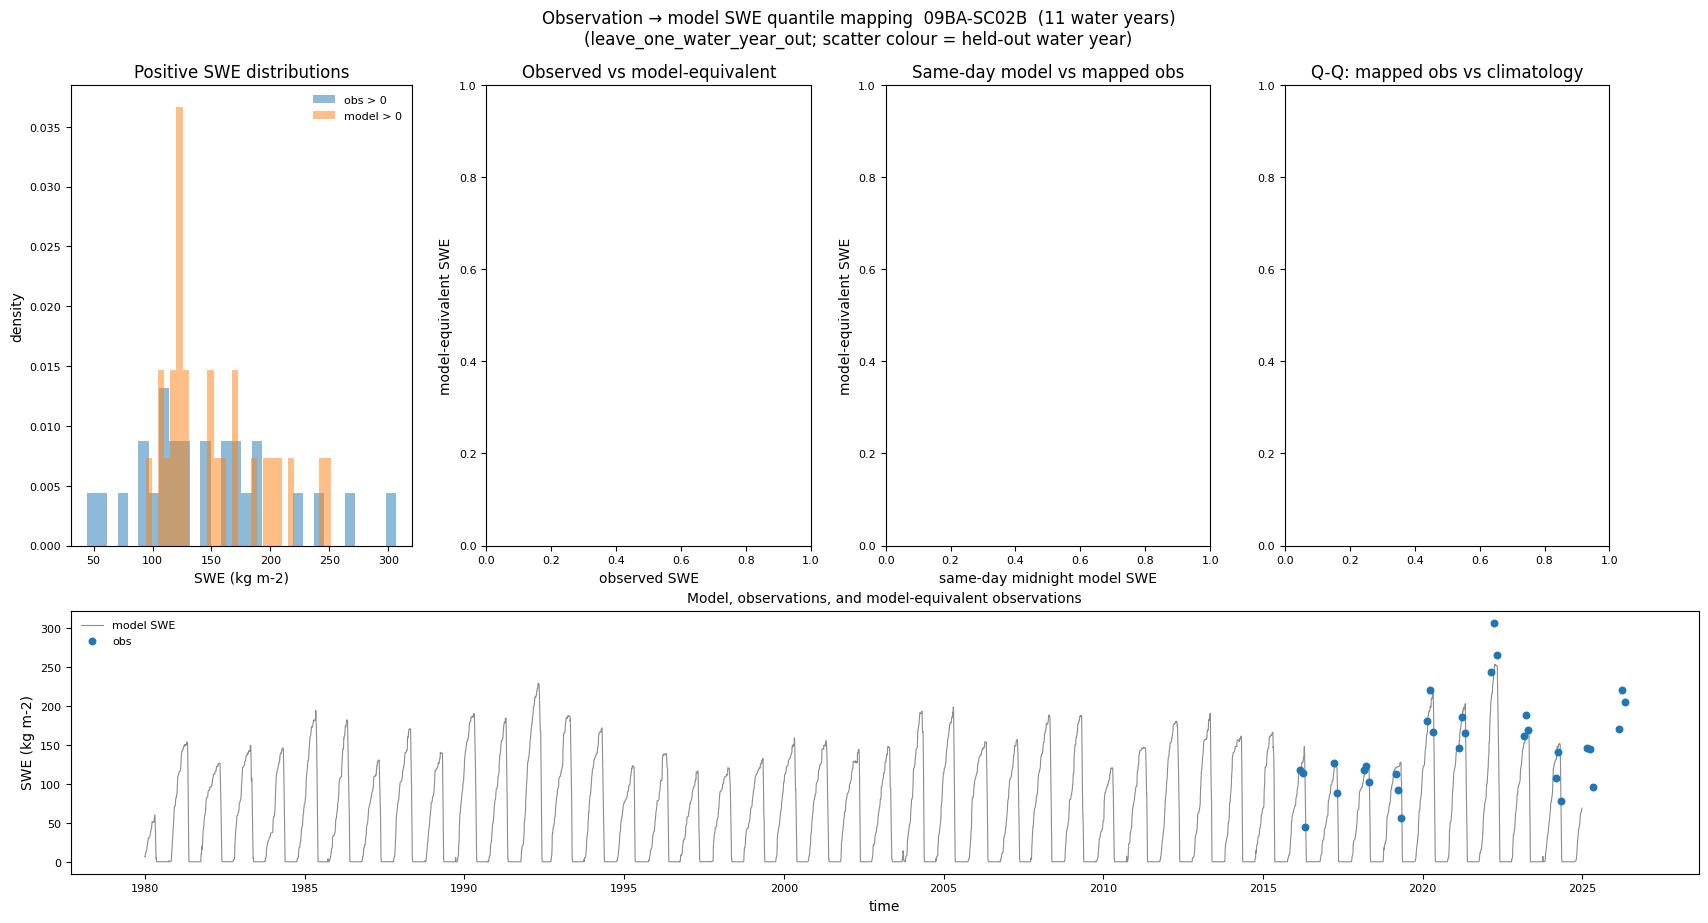

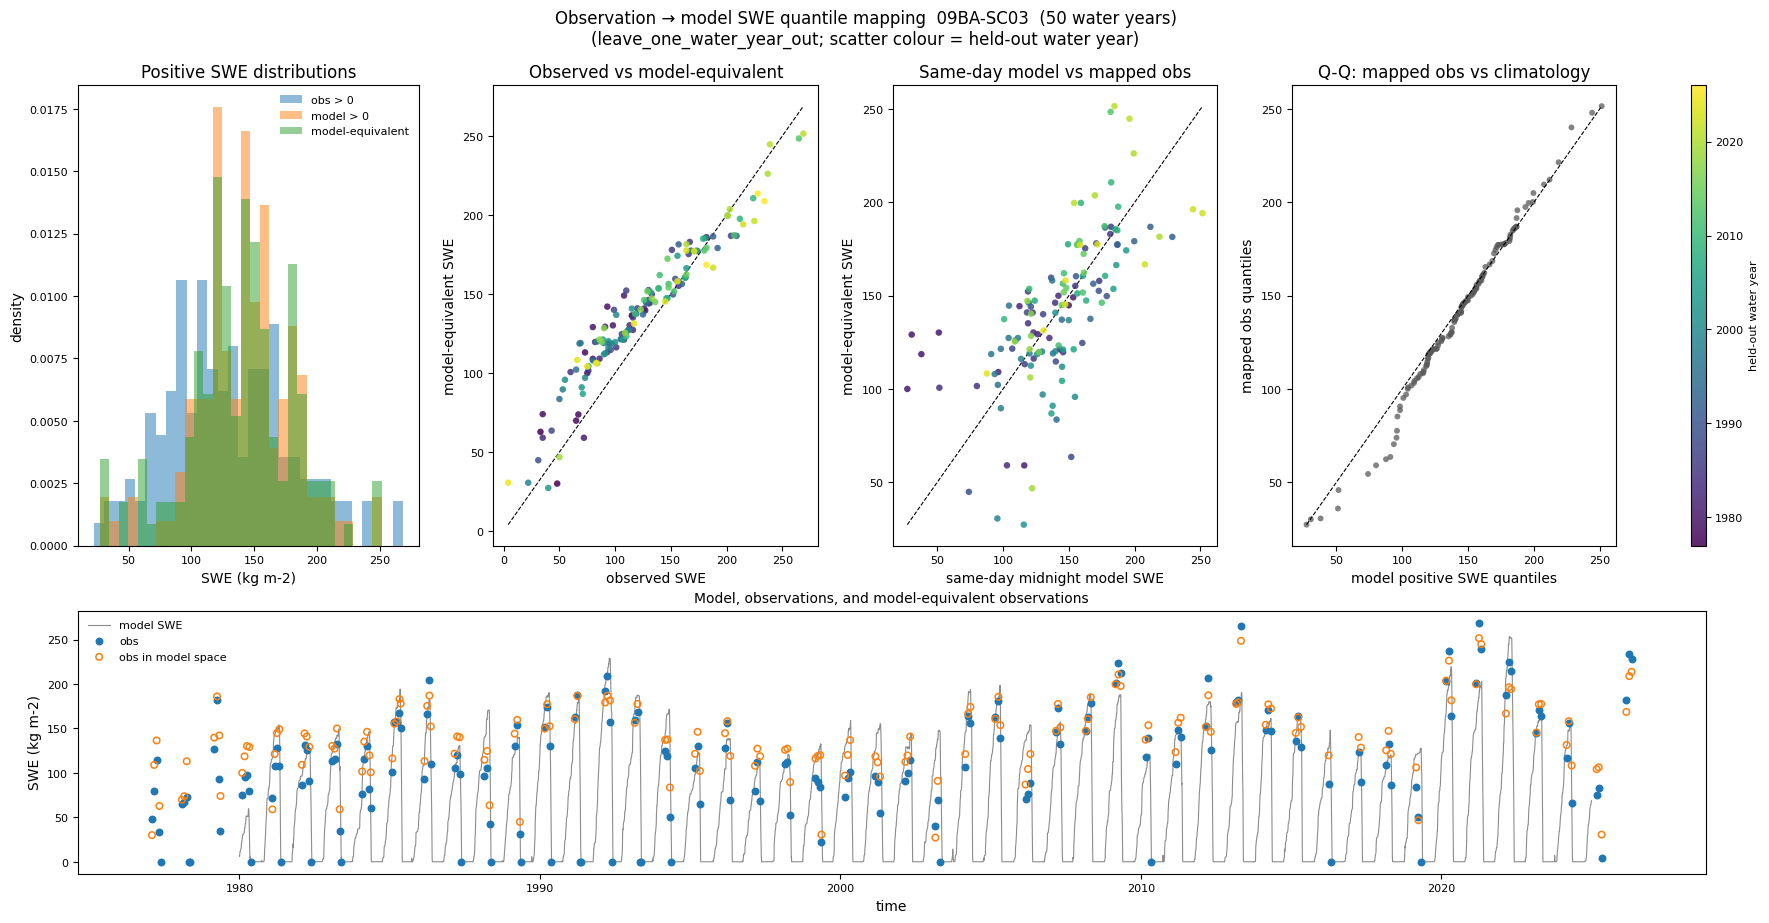

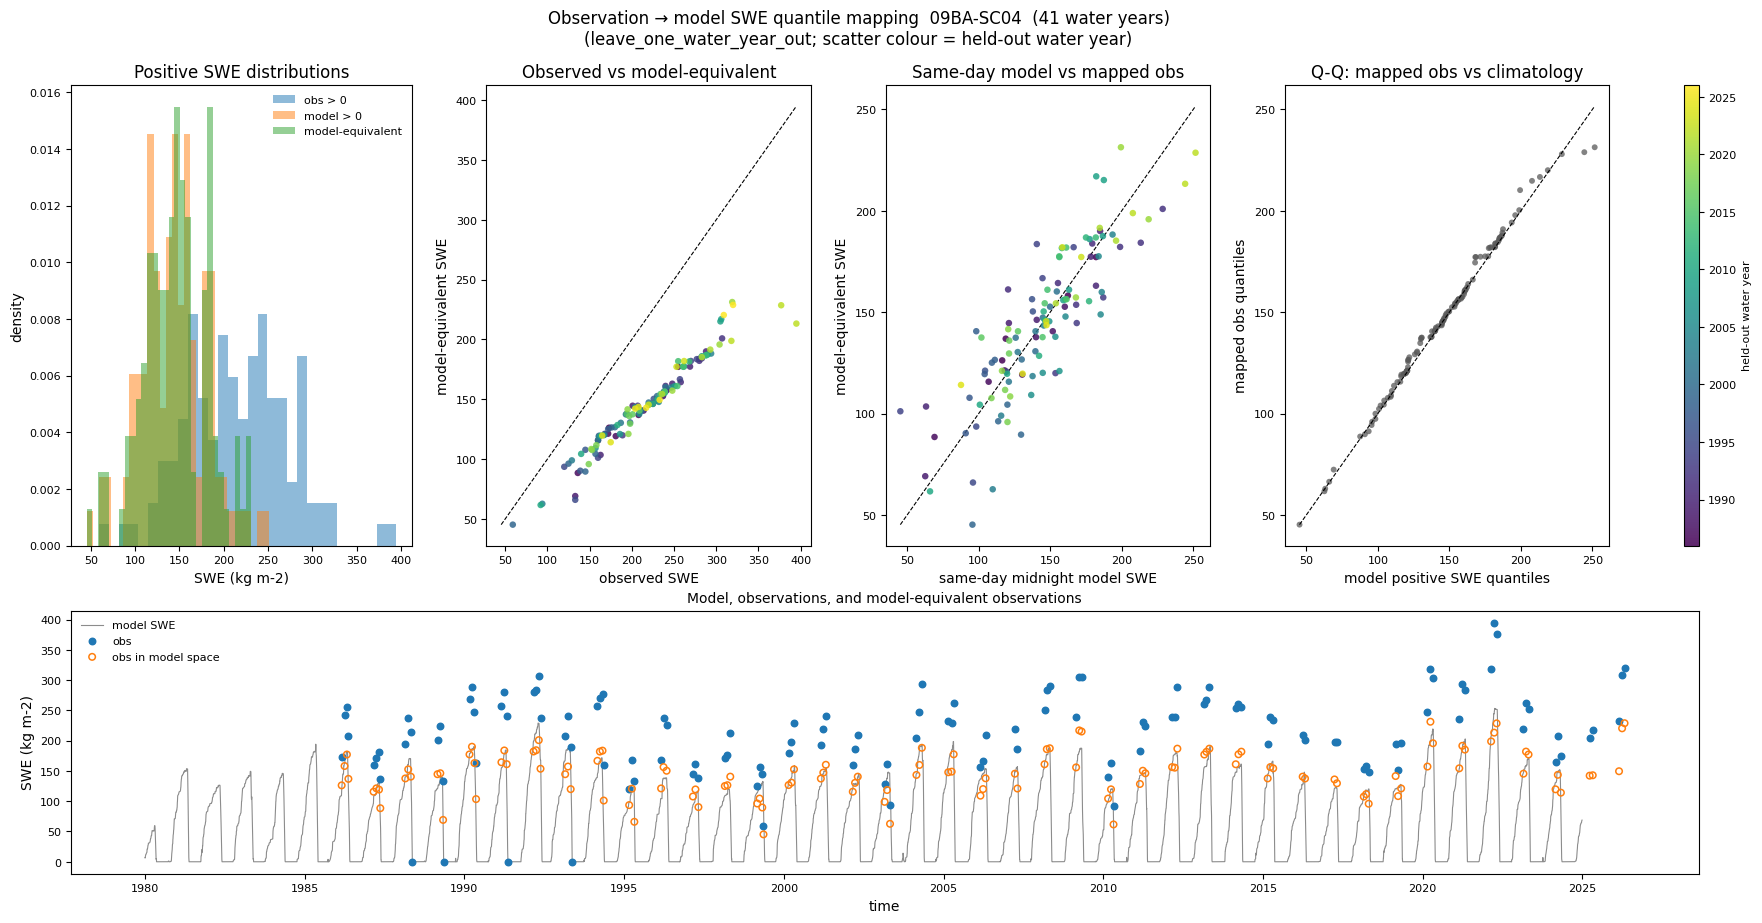

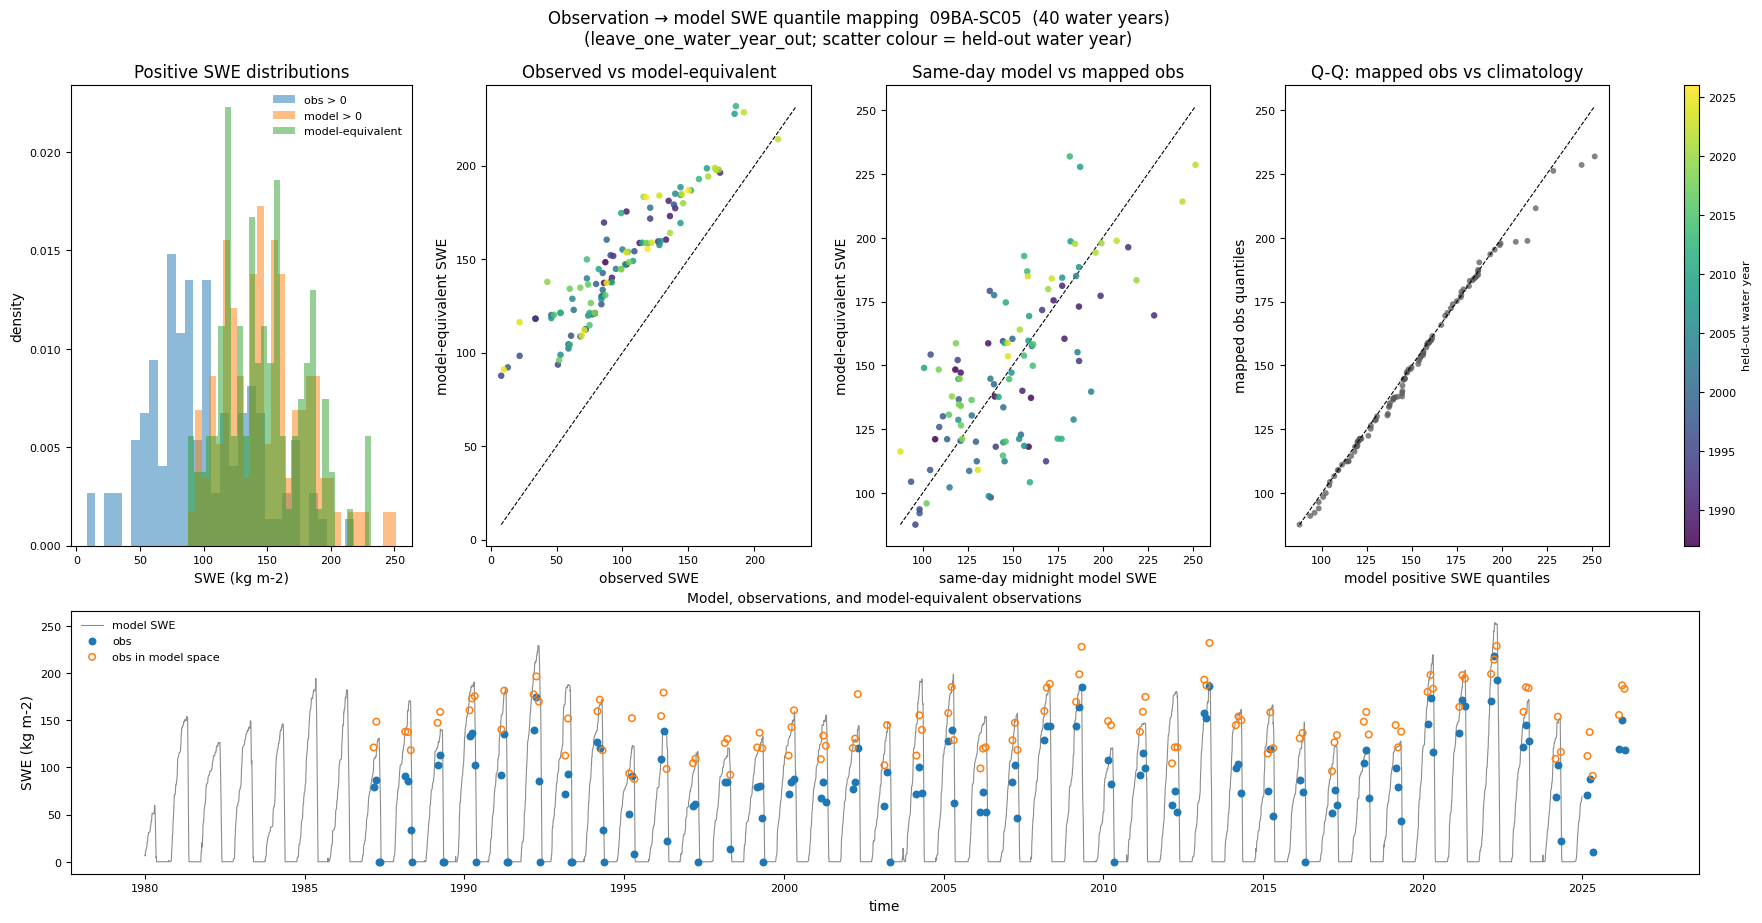

In [11]:
figures = []
for sid in stations_to_plot(mapped, include_screened=PLOT_SCREENED):
    fig = plot_station_diagnostics(mapped, station_id=sid, model=model)
    figures.append(fig)
    plt.show()

## Transformation check (not skill)

Among **mapped positive** values, compare the transformed sample to the colocated midnight model SWE on paired positive dates. Leave-one-year-out, zeros, and clipping mean this will not match $F_{\mathrm{mod}}$ exactly. It only checks that the transformation lands in model climatology space.

In [9]:
qq_rows = []
for sid in mapped.station_id.values:
    sub = mapped.sel(station_id=sid)
    mapped_mask = np.asarray(sub["mapping_flag"].values) == FLAG_MAPPED
    y_star = np.asarray(sub["swe_model_equivalent"].values)[mapped_mask]
    y_star = y_star[np.isfinite(y_star)]
    paired = np.asarray(sub["paired"].values)
    obs = np.asarray(sub["swe_obs"].values)
    model_vals = np.asarray(sub["swe_model"].values)
    model_pos = model_vals[paired & (obs > 0) & (model_vals > 0)]
    if y_star.size == 0 or model_pos.size == 0:
        qq_rows.append(
            {
                "station_id": sid,
                "n_mapped": int(y_star.size),
                "n_model_positive": int(model_pos.size),
                "mean_transformed": np.nan,
                "mean_model_positive": np.nan,
                "median_transformed": np.nan,
                "median_model_positive": np.nan,
            }
        )
        continue
    qq_rows.append(
        {
            "station_id": sid,
            "n_mapped": int(y_star.size),
            "n_model_positive": int(model_pos.size),
            "mean_transformed": float(np.mean(y_star)),
            "mean_model_positive": float(np.mean(model_pos)),
            "median_transformed": float(np.median(y_star)),
            "median_model_positive": float(np.median(model_pos)),
        }
    )
pd.DataFrame(qq_rows)

,station_id,n_mapped,n_model_positive,mean_transformed,mean_model_positive,median_transformed,median_model_positive
0,09BA-SC01,0,23,NaN,NaN,NaN,NaN
1,09BA-SC02,161,143,140.521431,140.744835,141.989905,142.896408
2,09BA-SC02A,150,132,140.647572,140.794245,142.651616,144.719602
3,09BA-SC02B,0,26,NaN,NaN,NaN,NaN
4,09BA-SC03,154,137,139.161483,142.184150,140.851735,144.618165
5,09BA-SC04,125,120,145.813312,144.676783,145.480601,145.121620
6,09BA-SC05,112,106,147.530701,149.348281,144.789663,146.188315


## Write mapped observations

The original `snw` series is preserved. New fields are added alongside `snw`.

In [10]:
out_ds = attach_mapped_variables(obs_ds, mapped, obs_variable="snw")
written = write_mapped_observations(out_ds, OUT_NC)
print("wrote", written)
print("variables:", list(out_ds.data_vars))
print("mapping_method:", out_ds.attrs.get("mapping_method"))
print("mapping_direction:", out_ds.attrs.get("mapping_direction"))
print("seasonal_window_days:", out_ds.attrs.get("seasonal_window_days"))
print("cross_validation:", out_ds.attrs.get("cross_validation"))
obs_ds.close()

wrote /Users/dcasson/GitHub/snowda/outputs/obs_qm/ross_yukon_swe_model_equivalent.nc
variables: ['snw', 'swe_obs', 'swe_model', 'swe_model_equivalent', 'quantile_obs', 'n_samples_mapping', 'mapping_flag', 'paired', 'n_paired', 'obs_zero_fraction', 'model_zero_fraction', 'both_positive_fraction', 'n_calendar_years', 'n_water_years', 'n_water_years_positive', 'first_year', 'last_year', 'passes_year_screen']
mapping_method: empirical_quantile_mapping
mapping_direction: observation_to_model
seasonal_window_days: 30
cross_validation: leave_one_water_year_out
